# Model Results: DenseNet-161 Scratch

Covers: training curves · per-subclass recall · PR/ROC curves · confusion matrix · test set results · validation vs test comparison.

In [1]:
import json
import os
import sys
import tempfile
from pathlib import Path


def find_project_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists() and (candidate / "outputs").exists():
            return candidate
    fallback = Path("/Users/jaumemalenacortes/Desktop/AABI/AAIB")
    if fallback.exists():
        return fallback
    return start


PROJECT_ROOT = find_project_root()
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "matplotlib-aaib"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except Exception:
    def display(obj):
        print(obj)
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    confusion_matrix,
)
from kvasir_triage.data.labels import BINARY_LABEL

# ── MODEL CONFIG ──────────────────────────────────────────────────────────────
MODEL_CONFIG = "densenet161_scratch"
DISPLAY_NAME = "DenseNet-161 Scratch"

RUNS_ROOT      = PROJECT_ROOT / "outputs" / "runs"
TEST_EVAL_ROOT = PROJECT_ROOT / "outputs" / "test_evaluation"
THRESHOLD      = 0.5

plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print(f"PROJECT_ROOT: {PROJECT_ROOT}")
print(f"RUNS_ROOT exists: {RUNS_ROOT.exists()} -> {RUNS_ROOT}")

PROJECT_ROOT: D:\Git\AAIB
RUNS_ROOT exists: True -> D:\Git\AAIB\outputs\runs


In [2]:
def find_run(config_name: str):
    candidates = sorted(
        [p for p in RUNS_ROOT.glob(f"{config_name}_fold0_*") if p.is_dir()],
        key=lambda p: p.stat().st_mtime,
    )
    if not candidates:
        candidates = sorted(
            [p for p in RUNS_ROOT.glob(f"{config_name}_*") if p.is_dir()],
            key=lambda p: p.stat().st_mtime,
        )
    return candidates[-1] if candidates else None


def load_metrics(run_dir) -> pd.DataFrame:
    path = run_dir / "metrics.jsonl"
    if not path.exists():
        return pd.DataFrame()
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if line:
                rows.append(json.loads(line))
    return pd.DataFrame(rows).replace({None: float("nan")})


def load_val_preds(run_dir):
    """Try eval_predictions_val.npz (evaluate.py), then val_preds_best.npz (trainer)."""
    for fname in ("eval_predictions_val.npz", "val_preds_best.npz"):
        path = run_dir / fname
        if not path.exists():
            continue
        d = np.load(path, allow_pickle=True)
        logits = d["logits"]
        labels = d["true_labels"] if "true_labels" in d.files else d["labels"]
        subs = d["subclasses"].astype(str)
        if logits.ndim == 2 and logits.shape[1] == 1:
            logits = logits[:, 0]
        return logits, labels, subs
    return None


def load_threshold_cal(run_dir) -> dict:
    path = run_dir / "threshold_calibration.json"
    if not path.exists():
        return {}
    return json.loads(path.read_text())


def load_test_results(config_name: str):
    path = TEST_EVAL_ROOT / f"{config_name}_test_results.json"
    if not path.exists():
        return None
    return json.loads(path.read_text())


# ── discover ──────────────────────────────────────────────────────────────────
run_dir = find_run(MODEL_CONFIG)
if run_dir:
    preds_ok = any(
        (run_dir / f).exists()
        for f in ("eval_predictions_val.npz", "val_preds_best.npz")
    )
    cal_ok  = (run_dir / "threshold_calibration.json").exists()
    test_ok = (TEST_EVAL_ROOT / f"{MODEL_CONFIG}_test_results.json").exists()
    print(f"Run:          {run_dir.name}")
    print(f"Val preds:    {'yes' if preds_ok else 'no  -- run evaluate.py first'}")
    print(f"Cal JSON:     {'yes' if cal_ok   else 'no  -- run evaluate.py first'}")
    print(f"Test results: {'yes' if test_ok  else 'no  -- run evaluate_test.py first'}")
else:
    print(f"No runs found for {MODEL_CONFIG}")

df_metrics = load_metrics(run_dir) if run_dir else pd.DataFrame()
val_data   = load_val_preds(run_dir) if run_dir else None
test_res   = load_test_results(MODEL_CONFIG)

Run:          densenet161_scratch_full_fold0
Val preds:    yes
Cal JSON:     yes
Test results: yes


## 1 · Training & Validation Curves

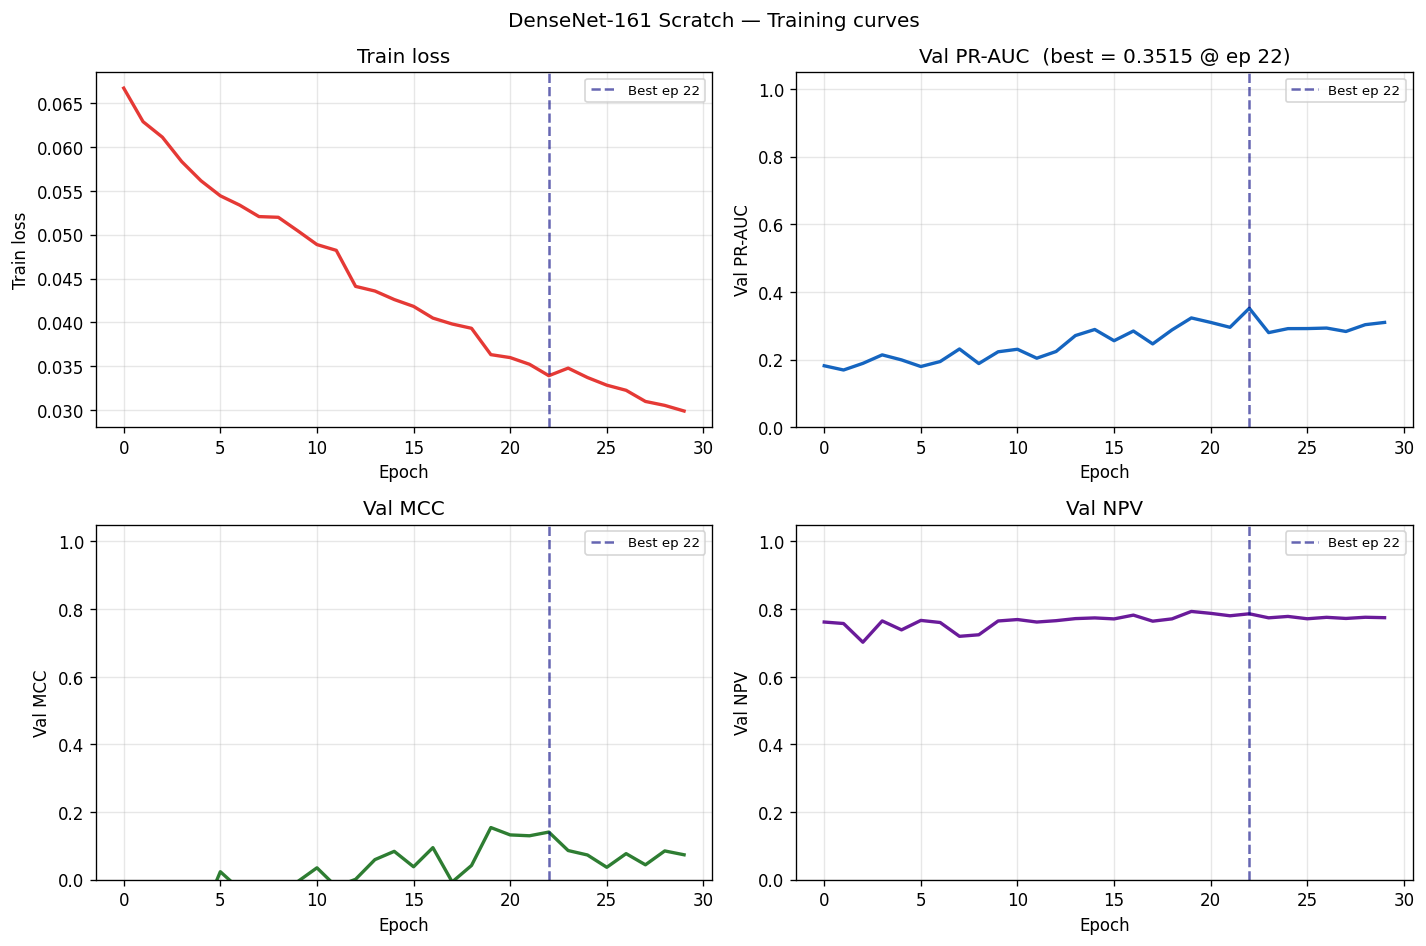

Total epochs: 30


In [3]:
if df_metrics.empty:
    print("No metrics.jsonl found -- train the model first.")
else:
    metric_specs = [
        ("train_loss", "Train loss",  "#e53935"),
        ("val_pr_auc", "Val PR-AUC",  "#1565C0"),
        ("val_mcc",    "Val MCC",     "#2e7d32"),
        ("val_npv",    "Val NPV",     "#6a1b9a"),
    ]
    avail = [(k, lbl, c) for k, lbl, c in metric_specs if k in df_metrics.columns]
    ncols = 2
    nrows = (len(avail) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 4 * nrows), squeeze=False)
    axes_flat = axes.flatten()

    best_ep = None
    if "val_pr_auc" in df_metrics.columns:
        best_idx = df_metrics["val_pr_auc"].idxmax()
        best_ep  = int(df_metrics.loc[best_idx, "epoch"])

    for i, (col, label, color) in enumerate(avail):
        ax = axes_flat[i]
        ax.plot(df_metrics["epoch"], df_metrics[col], color=color, lw=2)
        if "loss_switched" in df_metrics.columns:
            for ep in df_metrics[df_metrics["loss_switched"] == True]["epoch"]:
                ax.axvline(ep, color="orange", lw=1, ls=":", alpha=0.8, label="BCE\u2192Focal")
        if best_ep is not None:
            ax.axvline(best_ep, color="navy", ls="--", lw=1.5, alpha=0.6,
                       label=f"Best ep {best_ep}")
        ax.set_xlabel("Epoch"); ax.set_ylabel(label); ax.set_title(label)
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
        if col != "train_loss":
            ax.set_ylim(0, 1.05)

    for j in range(i + 1, len(axes_flat)):
        axes_flat[j].set_visible(False)

    if best_ep is not None and "val_pr_auc" in df_metrics.columns:
        best_prauc = float(df_metrics.loc[df_metrics["val_pr_auc"].idxmax(), "val_pr_auc"])
        pr_idx = next(
            (idx for idx, (k, _, _) in enumerate(avail) if k == "val_pr_auc"), None
        )
        if pr_idx is not None:
            axes_flat[pr_idx].set_title(
                f"Val PR-AUC  (best = {best_prauc:.4f} @ ep {best_ep})"
            )

    fig.suptitle(f"{DISPLAY_NAME} - Training curves", fontsize=12)
    fig.tight_layout()
    plt.show()
    print(f"Total epochs: {len(df_metrics)}")

## 2 · Per-subclass Recall over Training

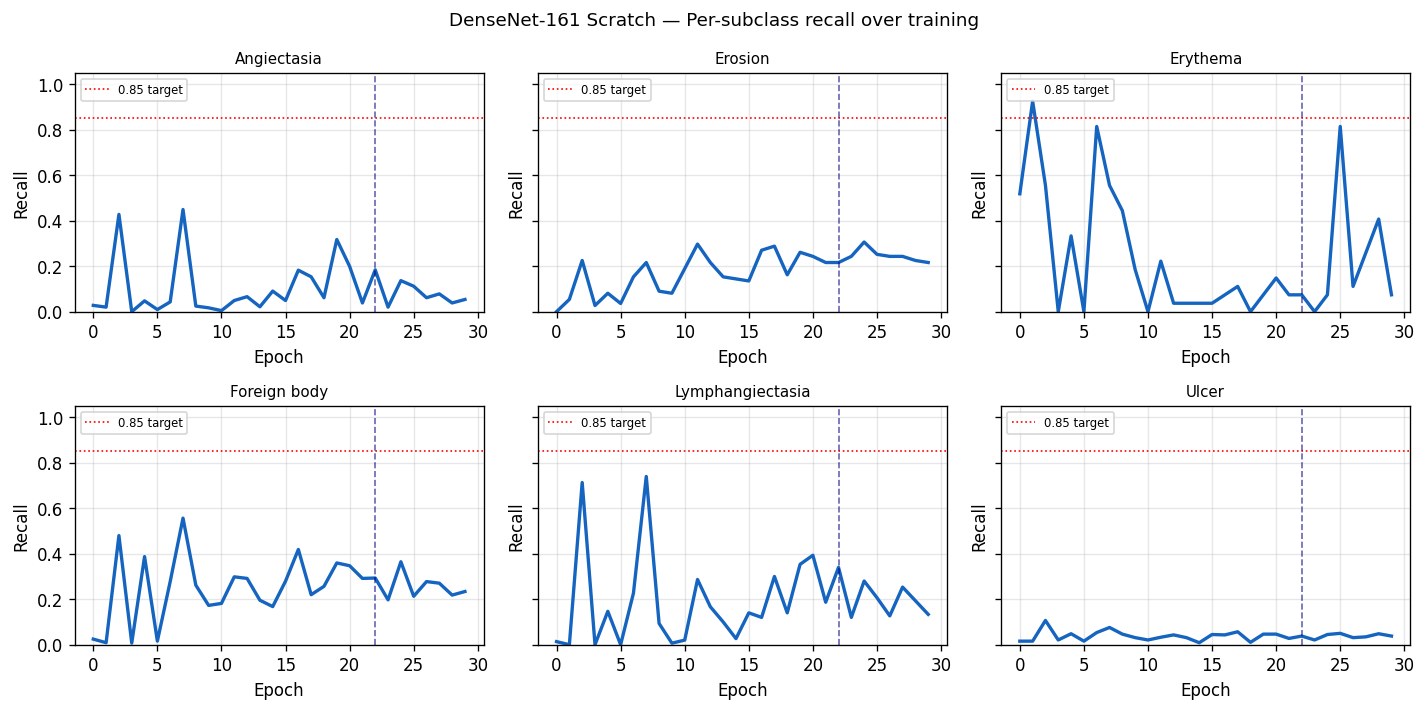

In [4]:
if df_metrics.empty:
    print("No metrics available.")
else:
    recall_cols = [c for c in df_metrics.columns if c.startswith("recall_")]
    if not recall_cols:
        print("No per-subclass recall columns in metrics.jsonl.")
    else:
        subclasses = [c.replace("recall_", "") for c in recall_cols]
        ncols = 3
        nrows = (len(subclasses) + ncols - 1) // ncols
        fig, axes = plt.subplots(
            nrows, ncols, figsize=(ncols * 4, nrows * 3), sharey=True, squeeze=False
        )
        axes_flat = axes.flatten()
        best_ep = (
            int(df_metrics.loc[df_metrics["val_pr_auc"].idxmax(), "epoch"])
            if "val_pr_auc" in df_metrics.columns
            else None
        )
        for i, (sub, col) in enumerate(zip(subclasses, recall_cols)):
            ax = axes_flat[i]
            ax.plot(df_metrics["epoch"], df_metrics[col], color="#1565C0", lw=2)
            ax.axhline(0.85, color="red", ls=":", lw=1, label="0.85 target")
            if best_ep is not None:
                ax.axvline(best_ep, color="navy", ls="--", lw=1, alpha=0.6)
            ax.set_title(sub, fontsize=9)
            ax.set_ylim(0, 1.05)
            ax.set_xlabel("Epoch"); ax.set_ylabel("Recall")
            ax.legend(fontsize=7); ax.grid(True, alpha=0.3)
        for j in range(i + 1, len(axes_flat)):
            axes_flat[j].set_visible(False)
        fig.suptitle(
            f"{DISPLAY_NAME} - Per-subclass recall over training", fontsize=11
        )
        fig.tight_layout()
        plt.show()

## 3 · Validation Metrics Summary

Best epoch (highest val PR-AUC) + threshold calibration from `evaluate.py` (if available).

In [5]:
if df_metrics.empty or "val_pr_auc" not in df_metrics.columns:
    print("No validation metrics available.")
else:
    best_idx = df_metrics["val_pr_auc"].idxmax()
    best = df_metrics.loc[best_idx]
    print(f"Best epoch: {int(best['epoch'])}")

    rows = []
    for col, label in [("val_pr_auc", "PR-AUC"), ("val_mcc", "MCC"), ("val_npv", "NPV")]:
        if col in best.index and not pd.isna(best[col]):
            rows.append({"Metric": label, "Validation (best epoch)": round(float(best[col]), 4)})
    if rows:
        display(pd.DataFrame(rows).set_index("Metric"))

    cal = load_threshold_cal(run_dir) if run_dir else {}
    if cal:
        print("\nThreshold calibration (from evaluate.py):")
        cal_rows = []
        for key, label in [("pr_auc", "PR-AUC"), ("mcc", "MCC"), ("npv", "NPV"), ("threshold", "threshold"), ("recall", "recall@t"), ("precision", "prec@t"), ("status", "status")]:
            if key in cal and cal[key] is not None:
                v = cal[key]
                cal_rows.append({
                    "Metric": label,
                    "Value": round(float(v), 4) if isinstance(v, (int, float)) else v,
                })
        if cal_rows:
            display(pd.DataFrame(cal_rows).set_index("Metric"))
    else:
        print("\n(No threshold_calibration.json -- run evaluate.py to generate it.)")

Best epoch: 22


,Validation (best epoch)
Metric,
PR-AUC,0.3515
MCC,0.1407
NPV,0.7860



Threshold calibration (from evaluate.py):


,Value
Metric,
PR-AUC,0.3515
MCC,0.1407
NPV,0.786
threshold,0.1453
recall@t,0.9002
prec@t,0.2638
status,ok


## 4 · Validation PR & ROC Curves

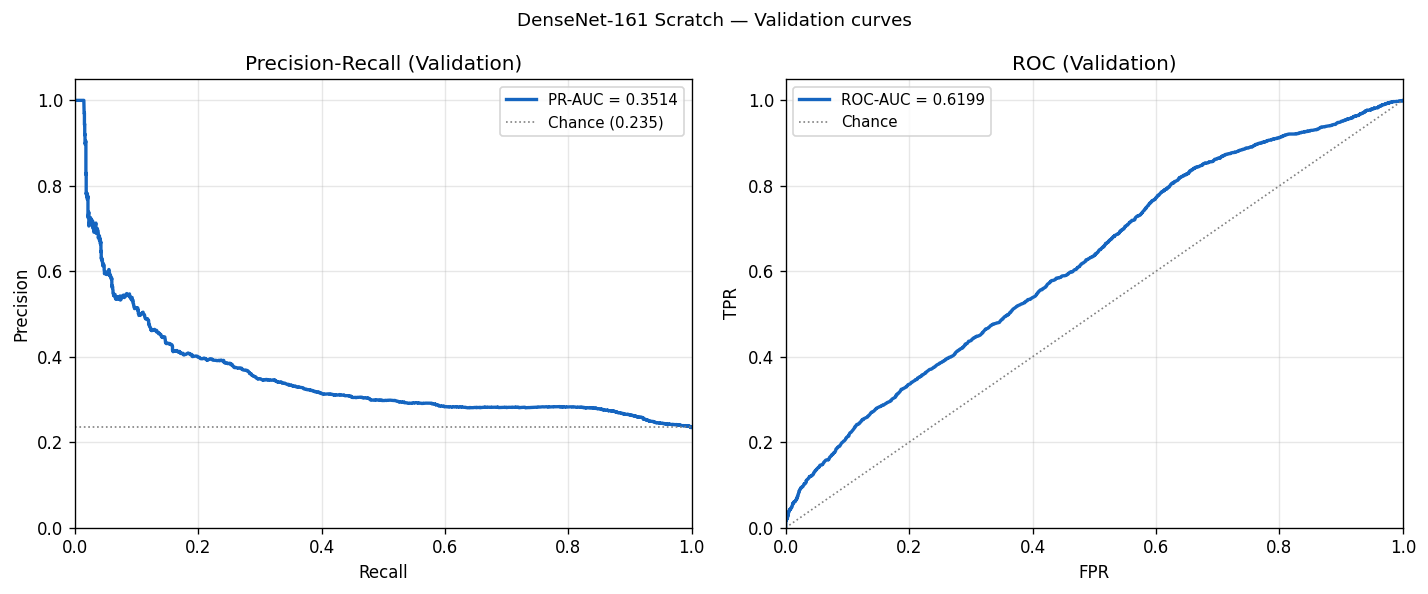

In [6]:
if val_data is None:
    print("No validation predictions. Run evaluate.py (or check val_preds_best.npz exists).")
else:
    logits, labels, _subs = val_data
    probs = 1 / (1 + np.exp(-logits))

    fig, (ax_pr, ax_roc) = plt.subplots(1, 2, figsize=(12, 5))

    prec, rec, _ = precision_recall_curve(labels, probs)
    ap = average_precision_score(labels, probs)
    ax_pr.plot(rec, prec, color="#1565C0", lw=2, label=f"PR-AUC = {ap:.4f}")
    ax_pr.axhline(labels.mean(), color="grey", ls=":", lw=1,
                  label=f"Chance ({labels.mean():.3f})")
    ax_pr.set_xlabel("Recall"); ax_pr.set_ylabel("Precision")
    ax_pr.set_xlim(0, 1); ax_pr.set_ylim(0, 1.05)
    ax_pr.set_title("Precision-Recall (Validation)"); ax_pr.legend(fontsize=9)
    ax_pr.grid(True, alpha=0.3)

    fpr, tpr, _ = roc_curve(labels, probs)
    ax_roc.plot(fpr, tpr, color="#1565C0", lw=2,
                label=f"ROC-AUC = {auc(fpr, tpr):.4f}")
    ax_roc.plot([0, 1], [0, 1], color="grey", ls=":", lw=1, label="Chance")
    ax_roc.set_xlabel("FPR"); ax_roc.set_ylabel("TPR")
    ax_roc.set_xlim(0, 1); ax_roc.set_ylim(0, 1.05)
    ax_roc.set_title("ROC (Validation)"); ax_roc.legend(fontsize=9)
    ax_roc.grid(True, alpha=0.3)

    fig.suptitle(f"{DISPLAY_NAME} - Validation curves", fontsize=11)
    fig.tight_layout()
    plt.show()

## 5 · Validation Confusion Matrix

Default threshold (t=0.5) and tuned threshold side by side.

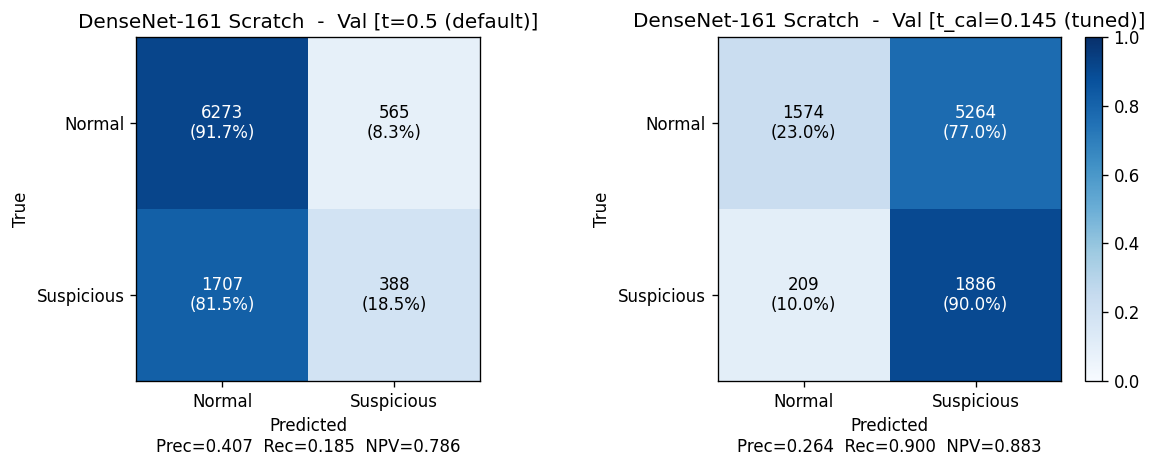

In [7]:
if val_data is None:
    print("No validation predictions available.")
else:
    logits, labels, _subs = val_data
    probs = 1 / (1 + np.exp(-logits))

    cal = load_threshold_cal(run_dir) if run_dir else {}
    t_cal = cal.get("threshold") or cal.get("closest_threshold")
    t_cal_str = (
        f"t_cal={t_cal:.3f}" if cal.get("threshold") is not None
        else f"closest_t={t_cal:.3f}" if t_cal is not None
        else None
    )

    thresholds = [(0.5, "t=0.5 (default)")]
    if t_cal is not None:
        thresholds.append((t_cal, f"{t_cal_str} (tuned)"))

    ncols = len(thresholds)
    fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4))
    axes = [axes] if ncols == 1 else list(axes)

    last_im = None
    for ax, (thresh, label) in zip(axes, thresholds):
        preds  = (probs >= thresh).astype(int)
        cm     = confusion_matrix(labels, preds)
        cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        last_im = ax.imshow(cm_pct, vmin=0, vmax=1, cmap="Blues")
        tick_labels = ["Normal", "Suspicious"]
        ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels)
        ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels)
        for i in range(2):
            for j in range(2):
                ax.text(
                    j, i, f"{cm[i, j]}\n({cm_pct[i, j]:.1%})",
                    ha="center", va="center", fontsize=10,
                    color="white" if cm_pct[i, j] > 0.5 else "black",
                )
        tp = cm[1, 1]; tn = cm[0, 0]; fp = cm[0, 1]; fn = cm[1, 0]
        prec_v = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
        rec_v  = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
        npv_v  = tn / (tn + fn) if (tn + fn) > 0 else float("nan")
        ax.set_title(f"{DISPLAY_NAME}  -  Val [{label}]")
        ax.set_ylabel("True")
        ax.set_xlabel(f"Predicted\nPrec={prec_v:.3f}  Rec={rec_v:.3f}  NPV={npv_v:.3f}")

    if last_im is not None:
        plt.colorbar(last_im, ax=axes[-1], fraction=0.046)
    fig.tight_layout()
    plt.show()

## 6 · Validation Per-subclass Analysis

Recall for suspicious classes, specificity for normal classes.

,binary_label,n,precision,recall,specificity,f1
subclass,,,,,,
Ileocecal valve,0,383,0.0,NaN,0.666,NaN
Normal clean mucosa,0,5148,0.0,NaN,0.921,NaN
Pylorus,0,213,0.0,NaN,0.859,NaN
Reduced mucosal view,0,1094,NaN,NaN,1.000,NaN
Angiectasia,1,652,1.0,0.184,NaN,0.311
Erosion,1,111,1.0,0.216,NaN,0.356
Erythema,1,27,1.0,0.074,NaN,0.138
Foreign body,1,573,1.0,0.295,NaN,0.456
Lymphangiectasia,1,150,1.0,0.340,NaN,0.507


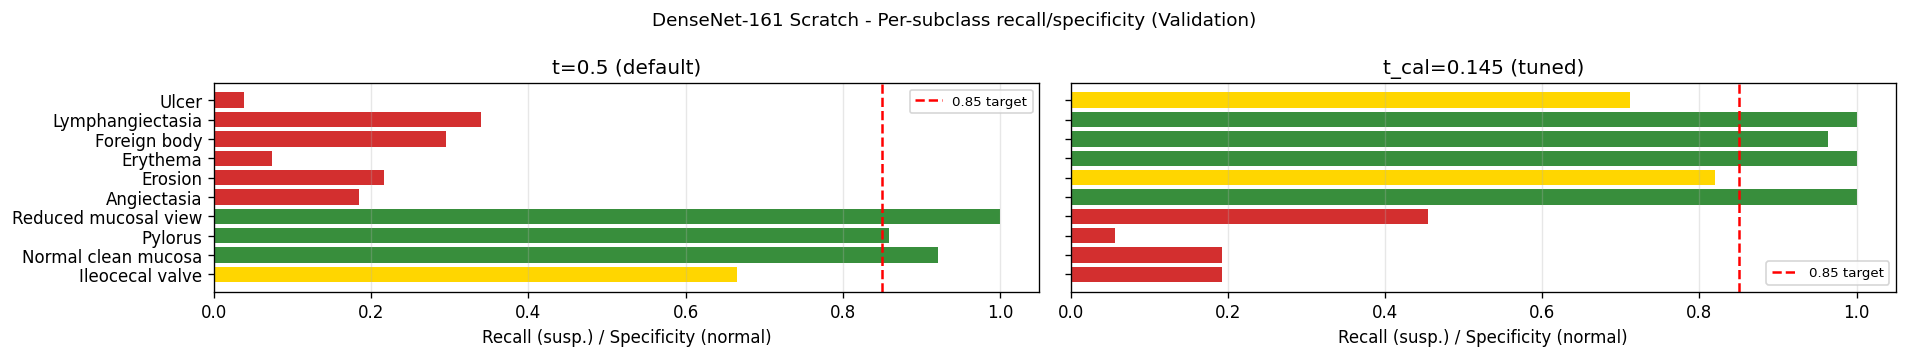

In [8]:
if val_data is None:
    print("No validation predictions available.")
else:
    logits, labels, subclasses = val_data
    probs  = 1 / (1 + np.exp(-logits))

    cal = load_threshold_cal(run_dir) if run_dir else {}
    t_cal = cal.get("threshold") or cal.get("closest_threshold")
    t_cal_str = (
        f"t_cal={t_cal:.3f}" if cal.get("threshold") is not None
        else f"closest_t={t_cal:.3f}" if t_cal is not None
        else None
    )

    preds  = (probs >= THRESHOLD).astype(int)
    rows = []
    for sub in sorted(np.unique(subclasses)):
        mask  = subclasses == sub
        y_t   = labels[mask]; y_p = preds[mask]
        tp    = int(((y_p == 1) & (y_t == 1)).sum())
        fp    = int(((y_p == 1) & (y_t == 0)).sum())
        tn    = int(((y_p == 0) & (y_t == 0)).sum())
        fn    = int(((y_p == 0) & (y_t == 1)).sum())
        rec   = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
        spec  = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
        prec  = tp / (tp + fp) if (tp + fp) > 0 else float("nan")
        f1    = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else float("nan")
        bl    = int(BINARY_LABEL.get(sub, -1))
        rows.append({
            "subclass": sub, "binary_label": bl,
            "n": int(mask.sum()),
            "precision": round(prec, 3), "recall": round(rec, 3),
            "specificity": round(spec, 3), "f1": round(f1, 3),
        })

    sub_df = pd.DataFrame(rows).sort_values(["binary_label", "subclass"])
    display(sub_df.set_index("subclass"))

    thresholds_to_show = [(THRESHOLD, "t=0.5 (default)")]
    if t_cal is not None:
        thresholds_to_show.append((t_cal, f"{t_cal_str} (tuned)"))

    n_subs = len(np.unique(subclasses))
    ncols  = len(thresholds_to_show)
    fig, axes = plt.subplots(1, ncols, figsize=(max(5, n_subs * 0.8) * ncols, 3),
                             sharey=True, squeeze=False)
    for ax, (thresh, thresh_label) in zip(axes[0], thresholds_to_show):
        preds_t = (probs >= thresh).astype(int)
        t_rows = []
        for sub in sorted(np.unique(subclasses)):
            mask = subclasses == sub
            y_t = labels[mask]; y_p = preds_t[mask]
            tp = int(((y_p == 1) & (y_t == 1)).sum())
            fp = int(((y_p == 1) & (y_t == 0)).sum())
            tn = int(((y_p == 0) & (y_t == 0)).sum())
            fn = int(((y_p == 0) & (y_t == 1)).sum())
            rec  = tp / (tp + fn) if (tp + fn) > 0 else float("nan")
            spec = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
            bl   = int(BINARY_LABEL.get(sub, -1))
            t_rows.append({"subclass": sub, "binary_label": bl,
                           "metric_val": rec if bl == 1 else spec})
        t_df = pd.DataFrame(t_rows).sort_values(["binary_label", "subclass"])
        t_labels = t_df["subclass"].tolist()
        t_vals   = t_df["metric_val"].tolist()
        bar_colors = [
            "#d32f2f" if (v != v or v < 0.5) else "#ffd600" if v < 0.85 else "#388e3c"
            for v in t_vals
        ]
        ax.barh(t_labels, t_vals, color=bar_colors)
        ax.axvline(0.85, color="red", ls="--", lw=1.5, label="0.85 target")
        ax.set_xlim(0, 1.05)
        ax.set_xlabel("Recall (susp.) / Specificity (normal)")
        ax.set_title(thresh_label)
        ax.legend(fontsize=8); ax.grid(True, alpha=0.3, axis="x")
    fig.suptitle(
        f"{DISPLAY_NAME} - Per-subclass recall/specificity (Validation)", fontsize=11
    )
    fig.tight_layout()
    plt.show()

## 7 · Test Set Results

Loaded from `outputs/test_evaluation/densenet161_scratch_test_results.json`.

Generate with:
```
python scripts/evaluate_test.py outputs/runs/densenet161_scratch_fold0_XXXX \
    --out outputs/test_evaluation/densenet161_scratch_test_results.json
```

In [ ]:
if test_res is None:
    test_path = TEST_EVAL_ROOT / f"{MODEL_CONFIG}_test_results.json"
    print(f"No test results at: {test_path}")
    print("Generate with:")
    print(f"  python scripts/evaluate_test.py outputs/runs/{MODEL_CONFIG}_fold0_XXXX")
    print(f"      --out outputs/test_evaluation/{MODEL_CONFIG}_test_results.json")
else:
    n_imgs = test_res["n_images"]
    n_ens  = test_res["n_models_ensembled"]
    m05    = test_res.get("metrics_at_0.5", {})
    mcal   = test_res.get("metrics_at_calibrated_threshold")

    print(f"Test set: {n_imgs} images  |  models ensembled: {n_ens}")

    def _safe_div(a, b):
        return round(a / b, 3) if b > 0 else float("nan")

    tp05 = m05.get("tp", 0); fp05 = m05.get("fp", 0); fn05 = m05.get("fn", 0)
    table_rows = [{
        "Threshold":  "0.5 (default)",
        "PR-AUC":     round(m05.get("pr_auc", float("nan")), 4),
        "MCC":        round(m05.get("mcc",    float("nan")), 4),
        "NPV":        round(m05.get("npv",    float("nan")), 4),
        "Precision":  _safe_div(tp05, tp05 + fp05),
        "Recall":     _safe_div(tp05, tp05 + fn05),
    }]
    if mcal:
        t = mcal.get("threshold", "?")
        tp_c = mcal.get("tp", 0); tn_c = mcal.get("tn", 0)
        fp_c = mcal.get("fp", 0); fn_c = mcal.get("fn", 0)
        denom_c = ((tp_c + fp_c) * (tp_c + fn_c) * (tn_c + fp_c) * (tn_c + fn_c)) ** 0.5
        mcc_c = round((tp_c * tn_c - fp_c * fn_c) / denom_c, 4) if denom_c > 0 else float("nan")
        table_rows.append({
            "Threshold":  f"t_cal={t:.3f} (tuned)" if isinstance(t, float) else f"t_cal={t} (tuned)",
            "PR-AUC":     " - ",
            "MCC":        mcc_c,
            "NPV":        round(mcal.get("npv",       float("nan")), 4),
            "Precision":  round(mcal.get("precision", float("nan")), 3),
            "Recall":     round(mcal.get("recall",    float("nan")), 3),
        })
    display(pd.DataFrame(table_rows).set_index("Threshold"))

    # ── Test confusion matrices ───────────────────────────────────────────────
    test_cm_data = []
    if all(k in m05 for k in ("tp", "fp", "tn", "fn")):
        test_cm_data.append((
            np.array([[m05["tn"], m05["fp"]], [m05["fn"], m05["tp"]]]),
            "t=0.5 (default)"
        ))
    if mcal and all(k in mcal for k in ("tp", "fp", "tn", "fn")):
        t_c = mcal.get("threshold", "?")
        t_c_str = f"t_cal={t_c:.3f}" if isinstance(t_c, float) else str(t_c)
        test_cm_data.append((
            np.array([[mcal["tn"], mcal["fp"]], [mcal["fn"], mcal["tp"]]]),
            f"{t_c_str} (tuned)"
        ))

    if test_cm_data:
        ncols = len(test_cm_data)
        fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 4))
        axes = [axes] if ncols == 1 else list(axes)
        last_im = None
        for ax, (cm_t, label) in zip(axes, test_cm_data):
            cm_pct = cm_t.astype(float) / cm_t.sum(axis=1, keepdims=True)
            last_im = ax.imshow(cm_pct, vmin=0, vmax=1, cmap="Oranges")
            tick_labels = ["Normal", "Suspicious"]
            ax.set_xticks([0, 1]); ax.set_xticklabels(tick_labels)
            ax.set_yticks([0, 1]); ax.set_yticklabels(tick_labels)
            for i in range(2):
                for j in range(2):
                    ax.text(
                        j, i, f"{cm_t[i, j]}\n({cm_pct[i, j]:.1%})",
                        ha="center", va="center", fontsize=10,
                        color="white" if cm_pct[i, j] > 0.5 else "black",
                    )
            tp_v = cm_t[1, 1]; tn_v = cm_t[0, 0]; fp_v = cm_t[0, 1]; fn_v = cm_t[1, 0]
            prec_v = tp_v / (tp_v + fp_v) if (tp_v + fp_v) > 0 else float("nan")
            rec_v  = tp_v / (tp_v + fn_v) if (tp_v + fn_v) > 0 else float("nan")
            npv_v  = tn_v / (tn_v + fn_v) if (tn_v + fn_v) > 0 else float("nan")
            ax.set_title(f"{DISPLAY_NAME}  -  Test [{label}]")
            ax.set_ylabel("True")
            ax.set_xlabel(f"Predicted\nPrec={prec_v:.3f}  Rec={rec_v:.3f}  NPV={npv_v:.3f}")
        if last_im is not None:
            plt.colorbar(last_im, ax=axes[-1], fraction=0.046)
        fig.tight_layout()
        plt.show()

    sub_recall     = test_res.get("subclass_recall", {})
    sub_recall_cal = test_res.get("subclass_recall_at_calibrated_threshold", {})
    recalls_to_show = []
    if sub_recall:
        recalls_to_show.append((sub_recall, "t=0.5 (default)"))
    if sub_recall_cal:
        t_c = mcal.get("threshold", "?") if mcal else "?"
        t_c_str = f"t_cal={t_c:.3f}" if isinstance(t_c, float) else str(t_c)
        recalls_to_show.append((sub_recall_cal, f"{t_c_str} (tuned)"))
    if recalls_to_show:
        n_subs = max(len(r[0]) for r in recalls_to_show)
        ncols  = len(recalls_to_show)
        fig, axes = plt.subplots(1, ncols, figsize=(max(5, n_subs * 0.8) * ncols, 3),
                                 sharey=True, squeeze=False)
        for ax, (sr, sr_label) in zip(axes[0], recalls_to_show):
            sr_items  = sorted(sr.items(), key=lambda x: x[1])
            sr_labels = [r[0] for r in sr_items]
            sr_vals   = [r[1] for r in sr_items]
            bar_colors = [
                "#d32f2f" if v < 0.5 else "#ffd600" if v < 0.85 else "#388e3c"
                for v in sr_vals
            ]
            ax.barh(sr_labels, sr_vals, color=bar_colors)
            ax.axvline(0.85, color="red", ls="--", lw=1.5, label="0.85 target")
            ax.set_xlim(0, 1.05); ax.set_xlabel("Recall")
            ax.set_title(sr_label)
            ax.legend(fontsize=8); ax.grid(True, alpha=0.3, axis="x")
        fig.suptitle(
            f"{DISPLAY_NAME} - Per-subclass recall (Test set)", fontsize=11
        )
        fig.tight_layout()
        plt.show()

## 8 · Validation vs Test Comparison

Val vs Test comparison:


,Validation,Test (t=0.5)
PR-AUC,0.3515,0.1542
MCC,0.1407,-0.0161
NPV (t=0.5),0.7860,0.8574
Recall (t_cal),0.9002,0.9079


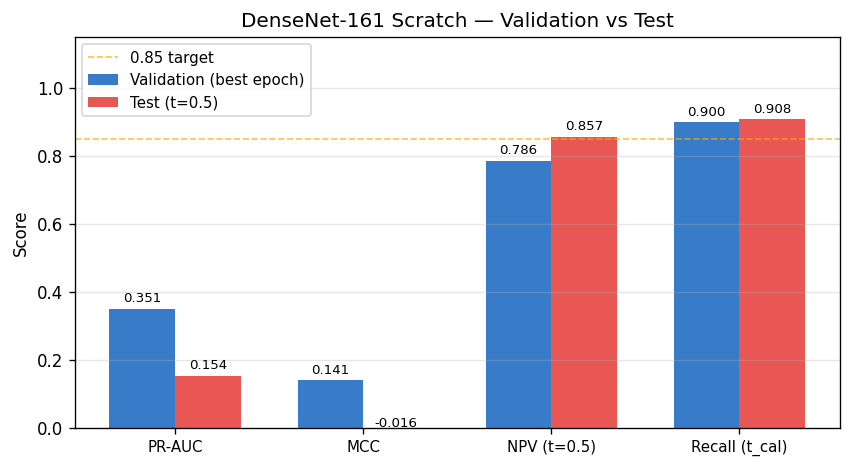

,Val,Test,Delta (Test - Val)
Metric,,,
PR-AUC,0.3515,0.1542,-0.1973
MCC,0.1407,-0.0161,-0.1568
NPV (t=0.5),0.7860,0.8574,0.0714
Recall (t_cal),0.9002,0.9079,0.0077


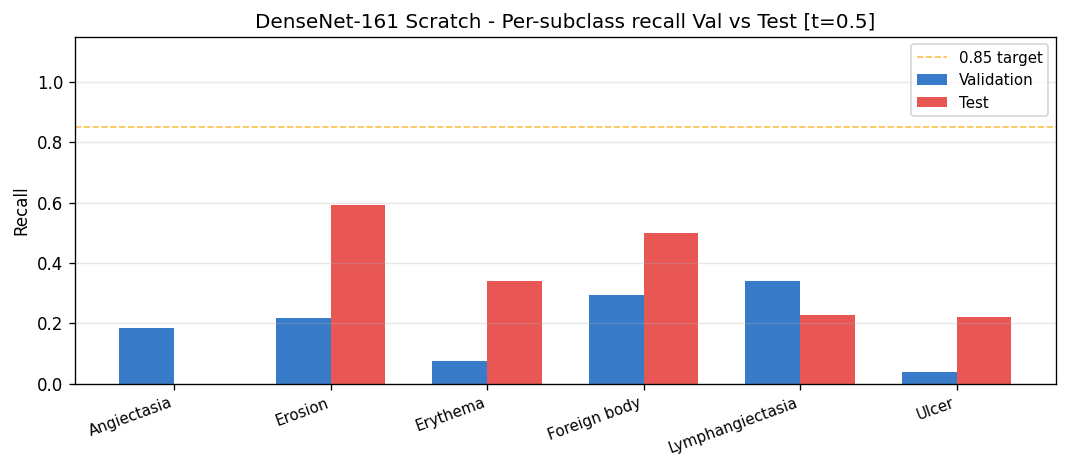

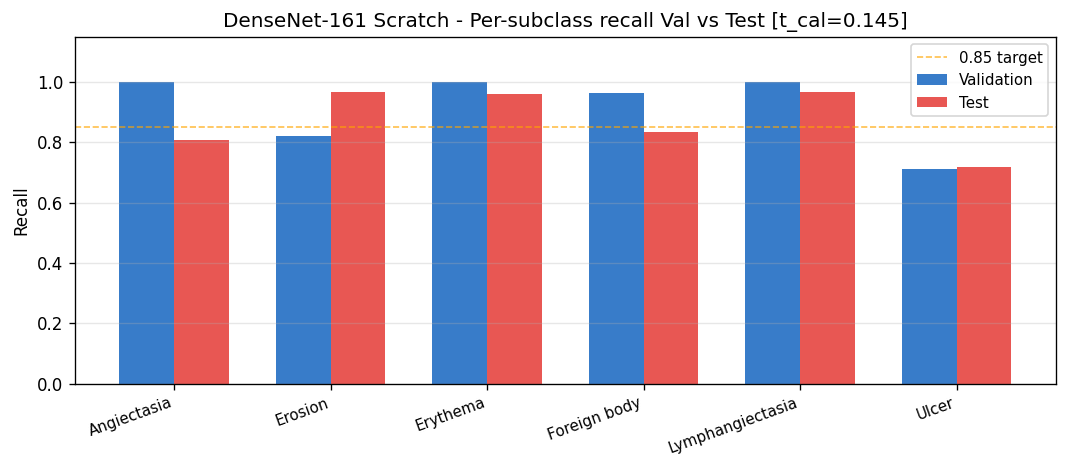

In [10]:
val_ok  = not df_metrics.empty and "val_pr_auc" in df_metrics.columns
test_ok = test_res is not None

if not val_ok:
    print("No validation metrics available.")
elif not test_ok:
    print("No test results. Run evaluate_test.py first.")
else:
    best   = df_metrics.loc[df_metrics["val_pr_auc"].idxmax()]
    cal    = load_threshold_cal(run_dir) if run_dir else {}
    m05    = test_res.get("metrics_at_0.5", {})
    mcal_t = test_res.get("metrics_at_calibrated_threshold") or {}

    compare = {
        "PR-AUC": {
            "Validation":   round(float(best.get("val_pr_auc", float("nan"))), 4),
            "Test (t=0.5)": round(float(m05.get("pr_auc",      float("nan"))), 4),
        },
        "MCC": {
            "Validation":   round(float(best.get("val_mcc", float("nan"))), 4),
            "Test (t=0.5)": round(float(m05.get("mcc",      float("nan"))), 4),
        },
        "NPV (t=0.5)": {
            "Validation":   round(float(best.get("val_npv", float("nan"))), 4),
            "Test (t=0.5)": round(float(m05.get("npv",      float("nan"))), 4),
        },
    }
    if cal.get("recall") is not None and mcal_t.get("recall") is not None:
        compare["Recall (t_cal)"] = {
            "Validation":   round(float(cal["recall"]), 4),
            "Test (t=0.5)": round(float(mcal_t["recall"]), 4),
        }

    compare_df = pd.DataFrame(compare).T
    print("Val vs Test comparison:")
    display(compare_df)

    metric_keys = list(compare.keys())
    val_vals    = [compare[k]["Validation"]   for k in metric_keys]
    test_vals   = [compare[k]["Test (t=0.5)"] for k in metric_keys]
    x     = np.arange(len(metric_keys))
    width = 0.35

    fig, ax = plt.subplots(figsize=(max(6, len(metric_keys) * 1.8), 4))
    bars1 = ax.bar(x - width / 2, val_vals,  width, label="Validation (best epoch)",
                   color="#1565C0", alpha=0.85)
    bars2 = ax.bar(x + width / 2, test_vals, width, label="Test (t=0.5)",
                   color="#e53935", alpha=0.85)
    ax.set_xticks(x); ax.set_xticklabels(metric_keys, fontsize=9)
    ax.set_ylim(0, 1.15); ax.set_ylabel("Score")
    ax.axhline(0.85, color="orange", ls="--", lw=1, alpha=0.7, label="0.85 target")
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis="y")
    ax.set_title(f"{DISPLAY_NAME} - Validation vs Test")

    for bars, vals in [(bars1, val_vals), (bars2, test_vals)]:
        for bar, val in zip(bars, vals):
            if isinstance(val, float) and val == val:  # skip NaN
                ax.text(
                    bar.get_x() + bar.get_width() / 2, val + 0.01,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=8,
                )
    fig.tight_layout()
    plt.show()

    delta_rows = []
    for k in metric_keys:
        v_val  = compare[k]["Validation"]
        v_test = compare[k]["Test (t=0.5)"]
        if isinstance(v_val, float) and isinstance(v_test, float) and v_val == v_val and v_test == v_test:
            delta_rows.append({
                "Metric": k, "Val": v_val, "Test": v_test,
                "Delta (Test - Val)": round(v_test - v_val, 4),
            })
    if delta_rows:
        delta_df = pd.DataFrame(delta_rows).set_index("Metric")
        display(delta_df)

    # Per-subclass recall: validation vs test
    if val_data is not None:
        val_logits, val_labels, val_subs = val_data
        val_probs = 1 / (1 + np.exp(-val_logits))
        t_c_val = cal.get("threshold") or cal.get("closest_threshold")

        sub_recall_05       = test_res.get("subclass_recall", {})
        sub_recall_cal_test = test_res.get("subclass_recall_at_calibrated_threshold", {})

        thresh_pairs = [(THRESHOLD, "t=0.5", sub_recall_05)]
        if t_c_val is not None and sub_recall_cal_test:
            thresh_pairs.append(
                (t_c_val, f"t_cal={t_c_val:.3f}", sub_recall_cal_test)
            )

        for thresh, thresh_label, test_recalls in thresh_pairs:
            preds_val = (val_probs >= thresh).astype(int)
            val_sub_recalls = {}
            for sub in np.unique(val_subs):
                mask = val_subs == sub
                y_t = val_labels[mask]; y_p = preds_val[mask]
                if y_t.sum() == 0:
                    continue
                tp = int(((y_p == 1) & (y_t == 1)).sum())
                fn = int(((y_p == 0) & (y_t == 1)).sum())
                val_sub_recalls[sub] = tp / (tp + fn) if (tp + fn) > 0 else float("nan")

            all_subs = sorted(set(val_sub_recalls) | set(test_recalls))
            if not all_subs:
                continue

            val_r  = [val_sub_recalls.get(s, float("nan")) for s in all_subs]
            test_r = [test_recalls.get(s, float("nan"))    for s in all_subs]

            x     = np.arange(len(all_subs))
            width = 0.35
            fig, ax = plt.subplots(figsize=(max(6, len(all_subs) * 1.5), 4))
            ax.bar(x - width / 2, val_r,  width, label="Validation", color="#1565C0", alpha=0.85)
            ax.bar(x + width / 2, test_r, width, label="Test",       color="#e53935", alpha=0.85)
            ax.set_xticks(x); ax.set_xticklabels(all_subs, rotation=20, ha="right", fontsize=9)
            ax.set_ylim(0, 1.15); ax.set_ylabel("Recall")
            ax.axhline(0.85, color="orange", ls="--", lw=1, alpha=0.7, label="0.85 target")
            ax.legend(fontsize=9); ax.grid(True, alpha=0.3, axis="y")
            ax.set_title(
                f"{DISPLAY_NAME} - Per-subclass recall Val vs Test [{thresh_label}]"
            )
            fig.tight_layout()
            plt.show()